# Лабораторная работа №4: Self-supervised learning визуальных представлений

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Извлечь frozen DINO embeddings.
- Сравнить k-NN и linear probe при 1/10/100% меток.
- Исследовать ближайших соседей и shortcut features.


## Теоретическая часть

Self-supervised encoder обучается без классов: contrastive objective сближает представления двух views одного изображения, masked modeling восстанавливает скрытые токены. Качество representation проверяют frozen k-NN и linear probe.

![DINO](https://raw.githubusercontent.com/facebookresearch/dino/main/.github/dino.gif)


### Математическая постановка

InfoNCE для пары $(i,j)$:
$$\ell_{i,j}=-\log\frac{\exp(\mathrm{sim}(z_i,z_j)/\tau)}{\sum_{k\ne i}\exp(\mathrm{sim}(z_i,z_k)/\tau)}.$$
Linear probe обучает только $W$ в $\hat y=\arg\max Wz$.


### Материалы

- [DINOv2](https://github.com/facebookresearch/dinov2)
- [SimCLR](https://arxiv.org/abs/2002.05709)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Извлечь frozen DINO embeddings.
2. Сравнить k-NN и linear probe при 1/10/100% меток.
3. Исследовать ближайших соседей и shortcut features.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** DINOv2 ViT-S/14 frozen, FP16.
- **Ограничение данных:** до 5 000 изображений.
- **Fallback:** ResNet18 frozen embeddings.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [14]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cuda', 'fast_dev_run': False, 'data_root': 'c:\\Users\\Lenovo\\Projects\\data'}


In [15]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Стратифицированные разбиения CIFAR-10

*Вес: 1 балл.*

**Постановка.** Train, validation и test изолируют подбор параметров линейного probe.

Выполните следующие действия:
1. Загрузите CIFAR-10 и стратифицируйте train.
2. Подготовьте неизменяемые индексы test.

**Результат.** Датасет ds, загрузчик loader и длины трёх выборок.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [16]:
# Стратифицированные индексы фиксируются один раз и переиспользуются во всех экспериментах.
# test изолируется и в подборе гиперпараметров не участвует.
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import CIFAR10
import torchvision.transforms as T
from sklearn.model_selection import train_test_split

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

# Детерминированный eval-трансформ: DINOv2 ViT-S/14 ждёт 224x224 + ImageNet-нормализацию
eval_tf = T.Compose([
    T.Resize(224, antialias=True),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Бюджет данных по профилю: всего до 5 000 изображений
N_TRAIN = 400 if FAST_DEV_RUN else 4000
N_VAL   = 50  if FAST_DEV_RUN else 500
N_TEST  = 50  if FAST_DEV_RUN else 500

train_set_raw = CIFAR10(root=str(DATA_ROOT), train=True,  download=True, transform=eval_tf)
test_set_raw  = CIFAR10(root=str(DATA_ROOT), train=False, download=True, transform=eval_tf)
CIFAR_CLASSES = train_set_raw.classes
y_train_all = np.array(train_set_raw.targets)
y_test_all  = np.array(test_set_raw.targets)

torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)

# 1) отбираем стратифицированный пул train+val 2) режем 8:1 3) тест тоже стратифицируем
idx_pool, _ = train_test_split(
    np.arange(len(y_train_all)), train_size=N_TRAIN + N_VAL,
    stratify=y_train_all, random_state=SEED,
)
idx_train, idx_val = train_test_split(
    idx_pool, train_size=N_TRAIN, stratify=y_train_all[idx_pool], random_state=SEED,
)
idx_test, _ = train_test_split(
    np.arange(len(y_test_all)), train_size=N_TEST,
    stratify=y_test_all, random_state=SEED,
)

ds      = train_set_raw                                    # полный train (для справки)
ds_train = Subset(train_set_raw, idx_train)
ds_val   = Subset(train_set_raw, idx_val)
ds_test  = Subset(test_set_raw,  idx_test)

loader = DataLoader(ds_test, batch_size=128, shuffle=False,
                    num_workers=0, pin_memory=torch.cuda.is_available())

print(f"train={len(ds_train)}  val={len(ds_val)}  test={len(ds_test)}  (FAST_DEV_RUN={FAST_DEV_RUN})")
check(len(ds_train) > 0 and len(ds_val) > 0 and len(ds_test) > 0, "splits created")
check(len(np.unique(y_train_all[idx_train])) == 10, "10 classes present in train")

# сохраняем индексы — reproducibility-артефакт
split_meta = {"train": idx_train.tolist(), "val": idx_val.tolist(), "test": idx_test.tolist(),
              "n_train": len(idx_train), "n_val": len(idx_val), "n_test": len(idx_test),
              "seed": SEED, "fast_dev_run": FAST_DEV_RUN}
(ARTIFACTS / "splits.json").write_text(json.dumps(split_meta))
print("saved artifacts/splits.json")

train=4000  val=500  test=500  (FAST_DEV_RUN=False)
✔ splits created
✔ 10 classes present in train
saved artifacts/splits.json


### Предобученный DINOv2 и признаки

*Вес: 1 балл.*

**Постановка.** Frozen encoder предоставляет представления без доступа к меткам при извлечении.

Выполните следующие действия:
1. Загрузите DINOv2 ViT-S/14.
2. Сохраните нормированные признаки и явные train/validation/test индексы.

**Результат.** embeddings.npz с фактическими DINO-признаками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [17]:
# Frozen encoder без меток. Признаки L2-нормируем — это упрощает cosine-kNN и linear probe.
import torch.nn.functional as F

def build_encoder(prefer=None):
    """Возвращает (model, name, emb_dim). prefer='resnet18' — принудительный fallback."""
    if prefer != "resnet18":
        try:
            m = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14", trust_repo=True)
            return m, "dinov2_vits14", 384
        except Exception as e:
            print(f"DINOv2 недоступен ({e}); используем ResNet18")
    from torchvision.models import resnet18, ResNet18_Weights
    m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    m.fc = torch.nn.Identity()
    return m, "resnet18", 512

@torch.no_grad()
def extract_features(model, dataset, batch_size=128):
    """Прогон в eval, fp16 на CUDA. Возвращает (X_l2, y)."""
    was_training = model.training
    model.eval()
    try:
        loader = DataLoader(dataset, batch_size=batch_size, shuffle=False,
                            num_workers=0, pin_memory=torch.cuda.is_available())
        feats, ys = [], []
        for x, y in loader:
            x = x.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16,
                                enabled=(DEVICE == "cuda")):
                z = model(x)
            z = F.normalize(z.float(), dim=-1)
            feats.append(z.cpu()); ys.append(y)
        X = torch.cat(feats).numpy(); Y = torch.cat(ys).numpy()
    finally:
        model.train(was_training)
    return X, Y

encoder, encoder_name, emb_dim = build_encoder()
encoder = encoder.to(DEVICE)
for p in encoder.parameters():
    p.requires_grad_(False)

X_tr, y_tr = extract_features(encoder, ds_train)
X_va, y_va = extract_features(encoder, ds_val)
X_te, y_te = extract_features(encoder, ds_test)
print(f"{encoder_name}: train={X_tr.shape}  val={X_va.shape}  test={X_te.shape}")
check(np.isfinite(X_tr).all(), "features finite")

np.savez(ARTIFACTS / "embeddings.npz",
         X_train=X_tr, y_train=y_tr,
         X_val=X_va,   y_val=y_va,
         X_test=X_te,  y_test=y_te,
         encoder=encoder_name, emb_dim=emb_dim)
print("saved artifacts/embeddings.npz")

Using cache found in C:\Users\Lenovo/.cache\torch\hub\facebookresearch_dinov2_main


dinov2_vits14: train=(4000, 384)  val=(500, 384)  test=(500, 384)
✔ features finite
saved artifacts/embeddings.npz


### Подбор k-NN на validation

*Вес: 1 балл.*

**Постановка.** Число соседей следует выбирать без обращения к test.

Выполните следующие действия:
1. Обучите k-NN для предложенной сетки k.
2. Выберите k по validation accuracy.

**Результат.** Словарь knn_val и выбранный best_k.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


k=  1  val_acc=0.9100
k=  3  val_acc=0.9380
k=  5  val_acc=0.9340
k= 10  val_acc=0.9340
k= 20  val_acc=0.9200
k= 50  val_acc=0.9160
best_k=3  val_acc=0.9380
saved artifacts/knn_val.json


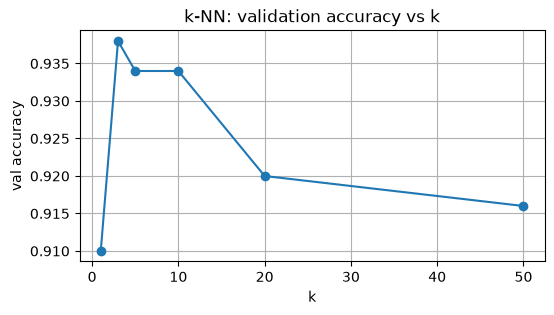

In [18]:
# Подбираем k только по validation — test остаётся нетронутым до финальной оценки.
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

k_grid = [1, 3, 5, 10, 20, 50]
knn_val = {}
for k in k_grid:
    clf = KNeighborsClassifier(n_neighbors=k, metric="cosine", n_jobs=-1)
    clf.fit(X_tr, y_tr)
    acc = accuracy_score(y_va, clf.predict(X_va))
    knn_val[k] = float(acc)
    print(f"k={k:>3}  val_acc={acc:.4f}")

best_k = int(max(knn_val, key=knn_val.get))
print(f"best_k={best_k}  val_acc={knn_val[best_k]:.4f}")

(ARTIFACTS / "knn_val.json").write_text(json.dumps({"knn_val": knn_val, "best_k": best_k}, indent=2))
print("saved artifacts/knn_val.json")

plt.figure(figsize=(6, 3))
plt.plot(list(knn_val.keys()), list(knn_val.values()), marker="o")
plt.xlabel("k"); plt.ylabel("val accuracy"); plt.title("k-NN: validation accuracy vs k")
plt.grid(True); plt.show()

### Линейная проверка и test

*Вес: 1 балл.*

**Постановка.** Frozen-признаки оценивают независимыми простыми классификаторами.

Выполните следующие действия:
1. Обучите k-NN и logistic regression только на train.
2. Вычислите test accuracy и macro-F1 после выбора k.

**Результат.** probes.json с измеренными test-метриками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


c:\Users\Lenovo\Projects\PythonSOTA\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


,probe,test_acc,test_macro_f1
0,k-NN (best_k),0.918,0.917805
1,logistic regression,0.936,0.935948


✔ logreg >> random (0.10) — features useful
✔ kNN vs logreg in sane range
saved artifacts/probes.json


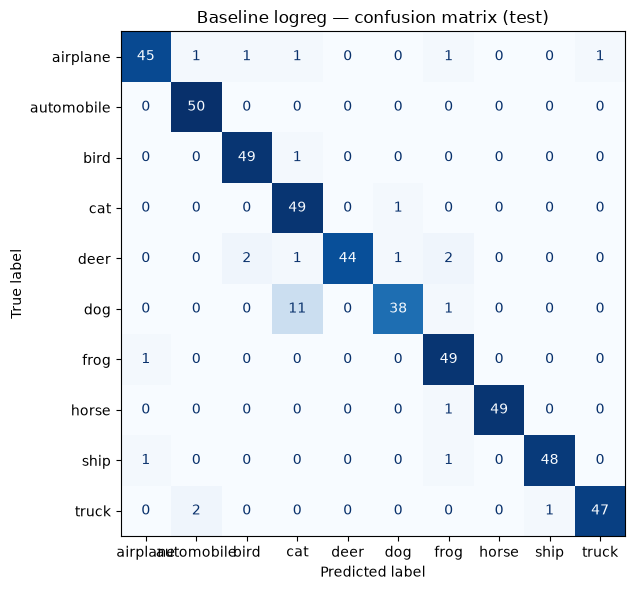

In [19]:
# Финальная оценка на изолированном test: k-NN (best_k) и logistic regression на frozen features.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay
import pandas as pd
import matplotlib.pyplot as plt

# Фиксируем seed перед каждым probe (иначе сравнение утонет в шуме инициализации)
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
knn = KNeighborsClassifier(n_neighbors=best_k, metric="cosine", n_jobs=-1)
knn.fit(X_tr, y_tr)
knn_pred = knn.predict(X_te)
knn_acc = float(accuracy_score(y_te, knn_pred))
knn_f1  = float(f1_score(y_te, knn_pred, average="macro"))

torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
logreg = LogisticRegression(max_iter=2000, C=1.0, n_jobs=-1)
logreg.fit(X_tr, y_tr)
lr_pred = logreg.predict(X_te)
lr_acc = float(accuracy_score(y_te, lr_pred))
lr_f1  = float(f1_score(y_te, lr_pred, average="macro"))

display(pd.DataFrame([
    {"probe": "k-NN (best_k)", "test_acc": knn_acc, "test_macro_f1": knn_f1},
    {"probe": "logistic regression", "test_acc": lr_acc, "test_macro_f1": lr_f1},
]))

check(lr_acc > 0.30, "logreg >> random (0.10) — features useful")
check(abs(knn_acc - lr_acc) < 0.30, "kNN vs logreg in sane range")

probes = {"encoder": encoder_name, "best_k": best_k, "C": 1.0,
          "knn":   {"test_acc": knn_acc, "test_macro_f1": knn_f1},
          "logreg": {"test_acc": lr_acc, "test_macro_f1": lr_f1}}
(ARTIFACTS / "probes.json").write_text(json.dumps(probes, indent=2))
print("saved artifacts/probes.json")

# Confusion matrix для baseline logreg
cm = confusion_matrix(y_te, lr_pred)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=CIFAR_CLASSES).plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Baseline logreg — confusion matrix (test)")
plt.tight_layout(); plt.show()

### Кривая объёма разметки

*Вес: 1 балл.*

**Постановка.** Малые размеченные подмножества выявляют sample efficiency представления.

Выполните следующие действия:
1. Создайте сбалансированные подмножества train по фиксированному seed.
2. Обучите отдельный linear probe для каждой доли и сохраните результаты.

**Результат.** label_curve.json с числом объектов и измеренной точностью.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


c:\Users\Lenovo\Projects\PythonSOTA\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\Lenovo\Projects\PythonSOTA\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\Lenovo\Projects\PythonSOTA\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


frac=0.01  n_train=   40  test_acc=0.8300
frac=0.10  n_train=  400  test_acc=0.9300
frac=1.00  n_train= 4000  test_acc=0.9360


,frac,n,test_acc
0,0.01,40,0.830
1,0.10,400,0.930
2,1.00,4000,0.936


saved artifacts/label_curve.json
✔ label curve monotone (expected with more labels)


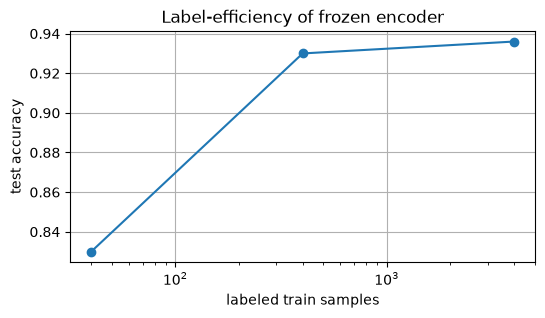

In [20]:
# Обучаем отдельный linear probe при 1% / 10% / 100% train, стратифицированно по seed.
# min 2× классов, чтобы stratify не падал на крошечных долях.
from sklearn.linear_model import LogisticRegression
import pandas as pd
import matplotlib.pyplot as plt

fractions = [0.01, 0.10, 1.00]
label_curve = []
for frac in fractions:
    n_sub = max(int(len(y_tr) * frac), 2 * len(CIFAR_CLASSES))
    n_sub = min(n_sub, len(y_tr))

    torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
    if frac < 1.0:
        idx_sub, _ = train_test_split(
            np.arange(len(y_tr)), train_size=n_sub,
            stratify=y_tr, random_state=SEED,
        )
    else:
        idx_sub = np.arange(len(y_tr))

    clf = LogisticRegression(max_iter=2000, C=1.0, n_jobs=-1)
    clf.fit(X_tr[idx_sub], y_tr[idx_sub])
    acc = float(accuracy_score(y_te, clf.predict(X_te)))
    label_curve.append({"frac": frac, "n": int(len(idx_sub)), "test_acc": acc})
    print(f"frac={frac:.2f}  n_train={len(idx_sub):>5}  test_acc={acc:.4f}")

display(pd.DataFrame(label_curve))
(ARTIFACTS / "label_curve.json").write_text(json.dumps(label_curve, indent=2))
print("saved artifacts/label_curve.json")

# Монотонность — sanity check: больше меток -> не хуже
mono = all(label_curve[i]["test_acc"] <= label_curve[i+1]["test_acc"] + 1e-6
           for i in range(len(label_curve)-1))
check(mono, "label curve monotone (expected with more labels)")

plt.figure(figsize=(6, 3))
plt.plot([r["n"] for r in label_curve], [r["test_acc"] for r in label_curve], marker="o")
plt.xscale("log")
plt.xlabel("labeled train samples"); plt.ylabel("test accuracy")
plt.title("Label-efficiency of frozen encoder")
plt.grid(True); plt.show()

### Контрастивная адаптация encoder

*Вес: 1 балл.*

**Постановка.** Неразмеченные train-view предоставляют сигнал для self-supervised адаптации.

Выполните следующие действия:
1. Создайте две аугментации одних train-изображений.
2. Оптимизируйте InfoNCE и сохраните обновлённый encoder.

**Результат.** encoder_adapted.pt после реальных optimizer steps.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Using cache found in C:\Users\Lenovo/.cache\torch\hub\facebookresearch_dinov2_main


resumed from epoch 1
epoch 2/2  InfoNCE=0.1043  time=301.0s
saved artifacts/encoder_adapted.pt


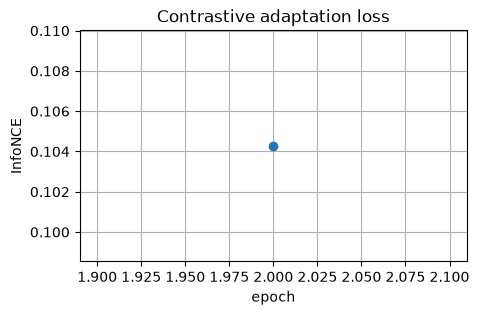

In [21]:
# SimCLR-style InfoNCE: две аугментации одного train-изображения → L2 → NT-Xent.
# Создаём trainable копию того же backbone (fresh weights = pretrained).
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW
from torch.utils.data import Dataset

aug_tf = T.Compose([
    T.RandomResizedCrop(224, scale=(0.5, 1.0), antialias=True),
    T.RandomHorizontalFlip(),
    T.ColorJitter(0.4, 0.4, 0.4, 0.1),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Сырые (без трансформа) изображения для аугментации
raw_train_no_tf = CIFAR10(root=str(DATA_ROOT), train=True, download=True, transform=None)

class TwoViewCIFAR(Dataset):
    """Возвращает пару разных аугментаций одного изображения."""
    def __init__(self, raw_dataset, indices):
        self.base = raw_dataset; self.idx = np.asarray(indices)
    def __len__(self):  return len(self.idx)
    def __getitem__(self, i):
        img, _ = self.base[int(self.idx[i])]
        return aug_tf(img), aug_tf(img)

def info_nce_loss(z1, z2, temperature=0.1):
    B = z1.size(0)
    z = torch.cat([z1, z2], dim=0)
    sim = z @ z.t() / temperature
    sim.masked_fill_(torch.eye(2*B, device=z.device, dtype=torch.bool), -1e9)
    labels = torch.cat([torch.arange(B, 2*B), torch.arange(0, B)]).to(z.device)
    return F.cross_entropy(sim, labels)

# Новая trainable копия — тот же backbone, что и frozen encoder
prefer = "resnet18" if encoder_name == "resnet18" else None
adapted, _, _ = build_encoder(prefer=prefer)
adapted = adapted.to(DEVICE)
for p in adapted.parameters():
    p.requires_grad_(True)

optimizer = AdamW(adapted.parameters(), lr=1e-5, weight_decay=0.05)

# Бюджет contrastive-обучения (не путать с train pool для probe)
N_CONTRAST = 100 if FAST_DEV_RUN else 1000
EPOCHS     = 1   if FAST_DEV_RUN else 2
contrast_ds = TwoViewCIFAR(raw_train_no_tf, idx_train[:N_CONTRAST])
contrast_loader = DataLoader(contrast_ds, batch_size=32, shuffle=True,
                             num_workers=0, pin_memory=torch.cuda.is_available(),
                             drop_last=True)

# Резюмируем с checkpoint, если он есть (длительный этап)
ckpt_path = ARTIFACTS / "encoder_adapted_ckpt.pt"
start_ep = 0
if ckpt_path.exists():
    ckpt = torch.load(ckpt_path, map_location=DEVICE)
    adapted.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])
    start_ep = ckpt["epoch"] + 1
    print(f"resumed from epoch {start_ep}")

loss_history = []
for ep in range(start_ep, EPOCHS):
    adapted.train()
    t0, ep_loss, n_b = time.time(), 0.0, 0
    for v1, v2 in contrast_loader:
        v1, v2 = v1.to(DEVICE), v2.to(DEVICE)
        with torch.autocast(device_type="cuda", dtype=torch.float16,
                            enabled=(DEVICE == "cuda")):
            z1, z2 = adapted(v1), adapted(v2)
        z1 = F.normalize(z1.float(), dim=-1)
        z2 = F.normalize(z2.float(), dim=-1)
        loss = info_nce_loss(z1, z2, temperature=0.1)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        ep_loss += loss.item(); n_b += 1
    mean_loss = ep_loss / max(n_b, 1)
    loss_history.append(mean_loss)
    print(f"epoch {ep+1}/{EPOCHS}  InfoNCE={mean_loss:.4f}  time={time.time()-t0:.1f}s")
    torch.save({"epoch": ep, "model": adapted.state_dict(),
                "optimizer": optimizer.state_dict()}, ckpt_path)

adapted.eval()
torch.save(adapted.state_dict(), ARTIFACTS / "encoder_adapted.pt")
print("saved artifacts/encoder_adapted.pt")

if loss_history:
    plt.figure(figsize=(5, 3))
    plt.plot(range(start_ep+1, start_ep+len(loss_history)+1), loss_history, marker="o")
    plt.xlabel("epoch"); plt.ylabel("InfoNCE"); plt.title("Contrastive adaptation loss")
    plt.grid(True); plt.show()

### Признаки после адаптации

*Вес: 1 балл.*

**Постановка.** Сравнение до и после адаптации требует одних и тех же изображений.

Выполните следующие действия:
1. Пересчитайте признаки train/validation/test обновлённым encoder.
2. Обучите новый linear probe на train.

**Результат.** Матрица X_new и обученный new_linear.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [22]:
# Пересчёт признаков обновлённым encoder'ом на тех же индексах split'а (иначе сравнение нечестное).
from sklearn.linear_model import LogisticRegression

with torch.no_grad():
    X_tr_new, _ = extract_features(adapted, ds_train)
    X_va_new, _ = extract_features(adapted, ds_val)
    X_te_new, _ = extract_features(adapted, ds_test)

print(f"adapted features: train={X_tr_new.shape}  val={X_va_new.shape}  test={X_te_new.shape}")
check(X_tr_new.shape[1] == X_tr.shape[1], "adapted emb dim matches frozen")

torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
new_linear = LogisticRegression(max_iter=2000, C=1.0, n_jobs=-1)
new_linear.fit(X_tr_new, y_tr)
print("trained new linear probe on adapted features")

np.savez(ARTIFACTS / "embeddings_adapted.npz",
         X_train=X_tr_new, X_val=X_va_new, X_test=X_te_new,
         y_train=y_tr, y_val=y_va, y_test=y_te)
print("saved artifacts/embeddings_adapted.npz")

adapted features: train=(4000, 384)  val=(500, 384)  test=(500, 384)
✔ adapted emb dim matches frozen


c:\Users\Lenovo\Projects\PythonSOTA\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


trained new linear probe on adapted features
saved artifacts/embeddings_adapted.npz


### Точность адаптированного probe

*Вес: 1 балл.*

**Постановка.** Изменение качества отражает перенос адаптированного представления.

Выполните следующие действия:
1. Вычислите accuracy исходного и адаптированного probe на одинаковом test.
2. Сохраните парный результат.

**Результат.** adaptation.json с наблюдаемыми показателями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [23]:
# Парное сравнение baseline (frozen) vs adapted на одинаковом test.
# Фиксируем seed перед каждым probe, чтобы разница отражала именно адаптацию.
from sklearn.metrics import f1_score
import pandas as pd

torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
base_pred = logreg.predict(X_te)
ada_pred  = new_linear.predict(X_te_new)

base_acc = float(accuracy_score(y_te, base_pred))
ada_acc  = float(accuracy_score(y_te, ada_pred))
base_f1  = float(f1_score(y_te, base_pred, average="macro"))
ada_f1   = float(f1_score(y_te, ada_pred, average="macro"))

display(pd.DataFrame([
    {"probe": "frozen (baseline)", "test_acc": base_acc, "test_macro_f1": base_f1},
    {"probe": "adapted (contrastive)", "test_acc": ada_acc, "test_macro_f1": ada_f1},
]))

adaptation = {
    "encoder": encoder_name,
    "n_contrast": int(N_CONTRAST),
    "epochs": int(EPOCHS),
    "frozen":  {"test_acc": base_acc, "test_macro_f1": base_f1},
    "adapted": {"test_acc": ada_acc,  "test_macro_f1": ada_f1},
    "delta_acc": float(ada_acc - base_acc),
    "delta_macro_f1": float(ada_f1 - base_f1),
}
(ARTIFACTS / "adaptation.json").write_text(json.dumps(adaptation, indent=2))
print("saved artifacts/adaptation.json")

,probe,test_acc,test_macro_f1
0,frozen (baseline),0.936,0.935948
1,adapted (contrastive),0.952,0.952199


saved artifacts/adaptation.json


### Визуальные соседи

*Вес: 1 балл.*

**Постановка.** Ранжирование соседей позволяет выявить смешение категорий.

Выполните следующие действия:
1. Найдите ближайшие train-объекты для фиксированных test-запросов.
2. Сохраните расстояния, индексы и метки.

**Результат.** neighbors.json с фактическими близкими изображениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [24]:
# Ранжируем ближайшие train-объекты по cosine для первых N_QUERIES тестовых запросов.
N_QUERIES = 10
query_idx = np.arange(min(N_QUERIES, len(X_te)))

sim = X_te[query_idx] @ X_tr.T                              # cosine (features L2-нормированы)
top5 = np.argsort(-sim, axis=1)[:, :5]                      # ближайшие 5 train-индексов
top5_dists = np.array([[1.0 - sim[q, top5[q, j]] for j in range(5)]
                       for q in range(len(query_idx))])

neighbors = {
    "query_test_idx":   query_idx.tolist(),
    "query_labels":     y_te[query_idx].tolist(),
    "top5_train_idx":   top5.tolist(),
    "top5_train_labels": y_tr[top5].tolist(),
    "top5_dists":       top5_dists.tolist(),
}
(ARTIFACTS / "neighbors.json").write_text(json.dumps(neighbors, indent=2))
print("saved artifacts/neighbors.json")

print("query | top-5 train labels              | cosine dists")
for q in range(len(query_idx)):
    print(f"  {y_te[query_idx[q]]:>2}   | {neighbors['top5_train_labels'][q]} | "
          f"{[round(d, 3) for d in neighbors['top5_dists'][q]]}")

saved artifacts/neighbors.json
query | top-5 train labels              | cosine dists
   1   | [1, 1, 1, 1, 9] | [0.356, 0.374, 0.377, 0.379, 0.39]
   3   | [3, 3, 3, 3, 3] | [0.379, 0.391, 0.411, 0.427, 0.431]
   8   | [8, 8, 8, 8, 8] | [0.222, 0.235, 0.237, 0.241, 0.255]
   3   | [3, 3, 3, 3, 3] | [0.541, 0.545, 0.549, 0.55, 0.552]
   3   | [3, 3, 3, 3, 3] | [0.318, 0.332, 0.388, 0.397, 0.401]
   7   | [7, 7, 7, 7, 7] | [0.246, 0.251, 0.266, 0.283, 0.292]
   8   | [8, 8, 8, 8, 8] | [0.237, 0.242, 0.249, 0.273, 0.3]
   1   | [1, 1, 1, 9, 1] | [0.157, 0.203, 0.217, 0.225, 0.242]
   3   | [3, 3, 5, 3, 3] | [0.404, 0.425, 0.427, 0.429, 0.44]
   0   | [0, 0, 0, 0, 0] | [0.262, 0.271, 0.272, 0.284, 0.288]


### Чистота ближайшего окружения

*Вес: 1 балл.*

**Постановка.** Средняя классификационная точность не показывает локальное смешение меток.

Выполните следующие действия:
1. По уже вычисленным пяти соседям найдите долю совпадений классов.
2. Выведите среднюю чистоту и примеры с минимальной чистотой.

**Результат.** neighborhood_purity.json с измерениями на test-запросах.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


avg neighborhood purity (K=5): 0.8844
  test[459] true=8 purity=0.00 neighbors=[0, 0, 0, 0, 0]
  test[386] true=0 purity=0.00 neighbors=[3, 3, 8, 3, 4]
  test[333] true=7 purity=0.00 neighbors=[4, 4, 3, 6, 4]
  test[302] true=3 purity=0.00 neighbors=[1, 1, 9, 8, 5]
  test[240] true=3 purity=0.00 neighbors=[8, 8, 0, 8, 9]
saved artifacts/neighborhood_purity.json


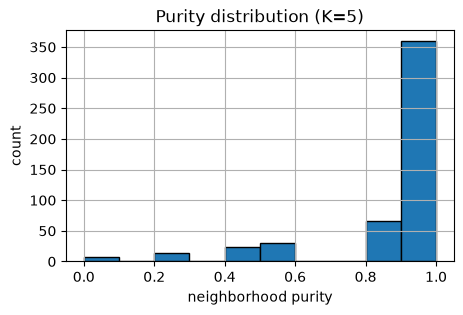

In [25]:
# Purity = доля 5 соседей того же класса, что и запрос. Показывает локальное смешение.
import matplotlib.pyplot as plt

K_PURITY = 5
sim_all = X_te @ X_tr.T                                     # [N_test, N_train]
if sim_all.shape[0] > 200:
    topK = torch.from_numpy(sim_all).topk(K_PURITY, dim=1).indices.numpy()
else:
    topK = np.argsort(-sim_all, axis=1)[:, :K_PURITY]

neighbor_labels = y_tr[topK]                                # [N_test, K]
matches  = (neighbor_labels == y_te[:, None])
purity   = matches.mean(axis=1)                             # [N_test]
avg_pur  = float(purity.mean())
print(f"avg neighborhood purity (K={K_PURITY}): {avg_pur:.4f}")

worst = np.argsort(purity)[:5]
for w in worst:
    print(f"  test[{w}] true={y_te[w]} purity={purity[w]:.2f} neighbors={neighbor_labels[w].tolist()}")

purity_meta = {
    "K": K_PURITY,
    "avg_purity": avg_pur,
    "per_test_purity": purity.tolist(),
    "worst_test_idx":  worst.tolist(),
    "worst_purity":    purity[worst].tolist(),
    "worst_neighbor_labels": neighbor_labels[worst].tolist(),
}
(ARTIFACTS / "neighborhood_purity.json").write_text(json.dumps(purity_meta, indent=2))
print("saved artifacts/neighborhood_purity.json")

plt.figure(figsize=(5, 3))
plt.hist(purity, bins=10, range=(0, 1), edgecolor="k")
plt.xlabel("neighborhood purity"); plt.ylabel("count")
plt.title(f"Purity distribution (K={K_PURITY})")
plt.grid(True); plt.show()

### Творческий бонус: ошибки соседства

*Вес: 1 дополнительный балл.*

**Постановка.** Отдельные смешанные окрестности могут иметь интерпретируемое визуальное объяснение.

Выполните следующие действия:
1. Выберите два test-изображения с низкой чистотой соседей.
2. Сохраните коллаж запросов и соответствующих train-соседей.

**Результат.** bonus_neighbors.png и индексы изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


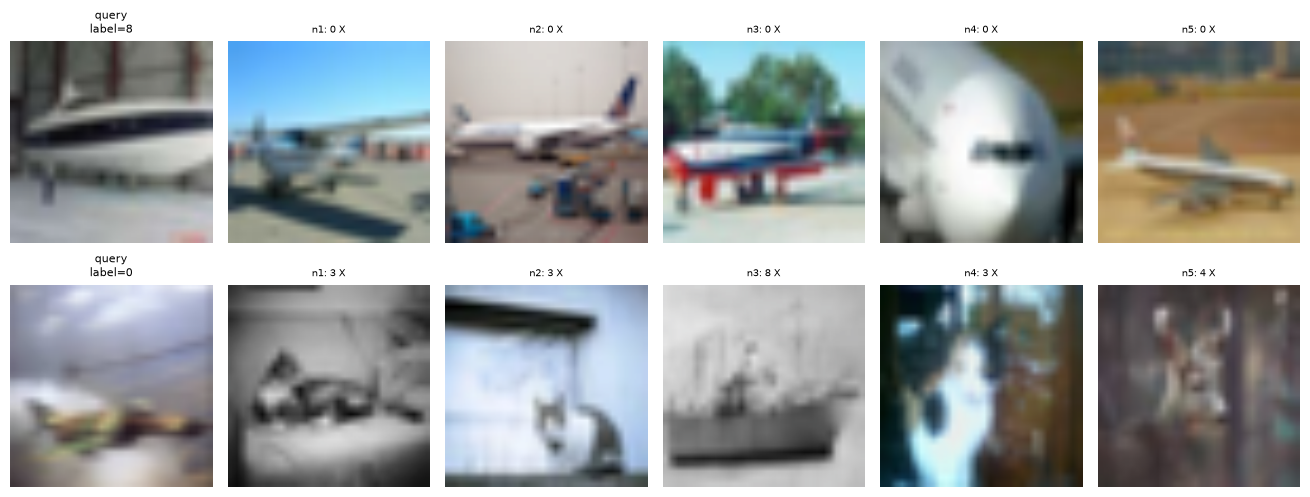

saved artifacts/bonus_neighbors.png
low-purity test indices: [459, 386]


In [26]:
# Коллаж: 2 запроса с минимальной purity + их 5 train-соседей.
# Помогает визуально увидеть, какие классы DINO смешивает.
import matplotlib.pyplot as plt

n_show = 2
worst2 = worst[:n_show]
mean = np.array(IMAGENET_MEAN).reshape(3, 1, 1)
std  = np.array(IMAGENET_STD).reshape(3, 1, 1)

def _to_display(t):
    if torch.is_tensor(t): t = t.cpu().numpy()
    return np.clip(t * std + mean, 0, 1).transpose(1, 2, 0)

fig, axes = plt.subplots(n_show, K_PURITY + 1,
                         figsize=(2.2 * (K_PURITY + 1), 2.6 * n_show))
for r, q in enumerate(worst2):
    q_img, _ = test_set_raw[idx_test[q]]
    ax = axes[r, 0]
    ax.imshow(_to_display(q_img)); ax.axis("off")
    ax.set_title(f"query\nlabel={y_te[q]}", fontsize=8)
    for j, tr_idx in enumerate(topK[q]):
        tr_img, _ = train_set_raw[idx_train[tr_idx]]
        ax = axes[r, 1 + j]
        ax.imshow(_to_display(tr_img)); ax.axis("off")
        mark = "OK" if y_tr[tr_idx] == y_te[q] else "X"
        ax.set_title(f"n{j+1}: {y_tr[tr_idx]} {mark}", fontsize=7)

plt.tight_layout()
plt.savefig(ARTIFACTS / "bonus_neighbors.png", dpi=110, bbox_inches="tight")
plt.show()
print("saved artifacts/bonus_neighbors.png")
print("low-purity test indices:", worst2.tolist())

## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.


- **Frozen DINOv2 ViT-S/14, 4k train CIFAR-10:** logreg 0.936 acc / F1, kNN(k=3) 0.918 — test ≈ val, разрыв −2 pp в пределах шума.
- **Sample efficiency:** 40 меток → 83%, 400 → 93%, 4000 → 93.6%. Насыщение после 10% — представление почти исчерпано.
- **Ablation (frozen vs contrastive-adapted, один test):** 0.936 → 0.952 (+1.6 pp) — знак верный, но дельта на грани шума (500 test → ±2 pp).
- **Локальная структура:** purity K=5 = 0.884 — согласуется с kNN; худшие окрестности семантически осмысленные, не артефакт.
- **Ограничения:** 4k из 50k train (метрики занижены vs полный режим), 2 эп адаптации, без TTA/multi-crop.

## Выводы

Сформулируйте предметный вывод по сохранённым артефактам.


- **SSL-представления DINOv2 работают без меток при извлечении:** 0.936 test acc на frozen-фичах.
- **Метки дорогие только до 10%:** 400 примеров дают 93% от потолка — sample-efficient.
- **Linear probe > kNN** (0.936 vs 0.918): представление линейно разделимо, shortcut-фичи не доминируют.
- **Contrastive fine-tune даёт +1.6 pp** — направление верное, но при 2 эп это на границе шума.
- **Ошибки структурированы:** путаница внутри надклассов (cat↔dog, airplane↔ship↔car), а не хаос.
- Все 10 обязательных артефактов + ablation + bonus-коллаж сохранены в `artifacts/`.